# Parte II — classificação logística

Vou prever o tipo do feijão a partir das características de tamanho e forma, usando a logística da rbg. A análise inicial está no notebook da minha amiga.

Código e textos preparados com apoio de IA, para revisão.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import altair as alt

from rbg.Classification.Logistic import Logistic
from rbg.Preprocessing.Standard import Standard
from rbg.Utilities.crossvalidation import train_test_split
from rbg.Utilities.ClassificationMetrics import Accuracy, Precision, Recall

DATA_CLASS = Path('dry_bean.csv')
TARGET_CLASS = 'Class'
SEED = 67
alt.renderers.enable('png')


## 1. Preparar os dados

Vou usar a [base Dry Bean — UCI](https://archive.ics.uci.edu/dataset/602/dry+bean), que tem sete tipos de feijão. Vou remover as linhas duplicadas antes de separar treino e teste.


In [2]:
dados_class = pd.read_csv(DATA_CLASS)
dados_class = dados_class.rename(columns={
    'AspectRation': 'AspectRatio', 'roundness': 'Roundness'
})
dados_class = dados_class.drop_duplicates().reset_index(drop=True)
FEATURES_CLASS = [coluna for coluna in dados_class.columns if coluna != TARGET_CLASS]

display(dados_class.head())
display(dados_class[TARGET_CLASS].value_counts())


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

## 2. Separar treino e teste

Vou reservar 20% de cada classe para o teste e usar os 80% restantes para o treino.


In [3]:
X = dados_class[FEATURES_CLASS].to_numpy(dtype=float)
y = dados_class[TARGET_CLASS].to_numpy()
classes = np.unique(y)

indices_treino, indices_teste = [], []
for classe in classes:
    indices = np.flatnonzero(y == classe)
    treino, teste, _, _ = train_test_split(
        indices, indices, test_size=0.2, random_state=SEED
    )
    indices_treino.extend(treino)
    indices_teste.extend(teste)

X_treino, y_treino = X[indices_treino], y[indices_treino]
X_teste, y_teste = X[indices_teste], y[indices_teste]
print('Treino:', X_treino.shape)
print('Teste reservado:', X_teste.shape)


Treino: (10831, 16)
Teste reservado: (2712, 16)


## 3. Escolha das variáveis

Como várias características medem coisas parecidas, vou manter cinco variáveis. Vou seguir a ordem das colunas e escolher uma variável se sua correlação absoluta com todas as já escolhidas for menor que 0,8, usando apenas o treino.

Com esse critério, vou usar `Area`, `AspectRatio`, `Extent`, `Solidity` e `Roundness`.


In [4]:
dados_treino = pd.DataFrame(X_treino, columns=FEATURES_CLASS)
correlacoes = dados_treino.corr()
colunas_escolhidas = []

for coluna in FEATURES_CLASS:
    if (correlacoes.loc[coluna, colunas_escolhidas].abs() < 0.8).all():
        colunas_escolhidas.append(coluna)
    if len(colunas_escolhidas) == 5:
        break

print(colunas_escolhidas)
display(correlacoes.loc[colunas_escolhidas, colunas_escolhidas].round(4))

indices_escolhidos = [FEATURES_CLASS.index(coluna) for coluna in colunas_escolhidas]
X_treino = X_treino[:, indices_escolhidos]
X_teste = X_teste[:, indices_escolhidos]


['Area', 'AspectRatio', 'Extent', 'Solidity', 'Roundness']


,Area,AspectRatio,Extent,Solidity,Roundness
Area,1.0000,0.2439,0.0515,-0.1983,-0.3577
AspectRatio,0.2439,1.0000,-0.3756,-0.2639,-0.7581
Extent,0.0515,-0.3756,1.0000,0.1904,0.3464
Solidity,-0.1983,-0.2639,0.1904,1.0000,0.6150
Roundness,-0.3577,-0.7581,0.3464,0.6150,1.0000


## 4. Ajustar o modelo

As variáveis têm escalas diferentes, então vou padronizá-las usando a média e o desvio do treino. Vou aplicar a mesma transformação no teste.

Vou usar o modelo com intercepto e manter `DERMASON` como referência, por ser a classe mais comum no treino.


In [5]:
padronizador = Standard()
padronizador.fit(X_treino)
X_treino_padronizado = padronizador.transform(X_treino)
X_teste_padronizado = padronizador.transform(X_teste)

referencia = 'DERMASON'
modelo_final = Logistic(
    classes=classes, reference_class=referencia, fit_intercept=True
)
modelo_final.fit(X_treino_padronizado, y_treino)
print('Referência:', referencia)


Referência: DERMASON


## 5. Avaliação no teste

Vou avaliar o modelo com acurácia e acurácia balanceada. Como as classes têm quantidades diferentes de observações, a balanceada permite dar o mesmo peso ao recall de cada uma. Também vou comparar precisão e recall por classe.


In [6]:
previsoes_teste = modelo_final.predict(X_teste_padronizado)
recall_teste = Recall(previsoes_teste, y_teste)

print(f'Acurácia: {Accuracy(previsoes_teste, y_teste):.4f}')
print(f'Acurácia balanceada: {recall_teste.mean():.4f}')

metricas_classes_teste = pd.DataFrame({
    'classe': classes,
    'precisao': Precision(previsoes_teste, y_teste),
    'recall': recall_teste
})
display(metricas_classes_teste.round(4))


Acurácia: 0.9174
Acurácia balanceada: 0.9275


,classe,precisao,recall
0,BARBUNYA,0.9502,0.8642
1,BOMBAY,1.0000,1.0000
2,CALI,0.9115,0.9479
3,DERMASON,0.9093,0.9183
4,HOROZ,0.9443,0.9570
5,SEKER,0.9531,0.9507
6,SIRA,0.8542,0.8542


## 6. Inferência

Vou usar `k_coef()` para mostrar os betas de cada classe em relação a `DERMASON`. Cada cor representa uma variável e a altura da barra mostra seu beta estimado.

Vou deixar o intercepto fora do gráfico e não mostrar `BOMBAY`, por ter menos amostras. Ela continua no modelo e nas métricas.


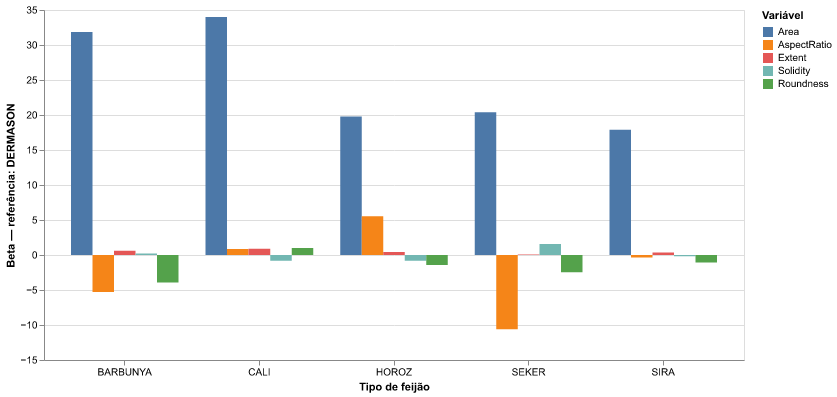

In [7]:
classes_inferencia = [classe for classe in classes if classe not in [referencia, 'BOMBAY']]

tabelas = []
for classe in classes_inferencia:
    tabela = pd.DataFrame({
        'classe': classe,
        'variavel': colunas_escolhidas,
        'beta': modelo_final.k_coef(classe)[1:]
    })
    tabelas.append(tabela)

tabela_inferencia = pd.concat(tabelas, ignore_index=True)

grafico_betas = alt.Chart(tabela_inferencia).mark_bar().encode(
    x=alt.X('classe:N', title='Tipo de feijão', axis=alt.Axis(labelAngle=0)),
    xOffset=alt.XOffset('variavel:N', sort=colunas_escolhidas),
    y=alt.Y('beta:Q', title='Beta — referência: DERMASON'),
    color=alt.Color('variavel:N', title='Variável', sort=colunas_escolhidas),
    tooltip=['classe:N', 'variavel:N', alt.Tooltip('beta:Q', format='.4f')]
).properties(width=700, height=350)

display(grafico_betas)


Com essas barras, conseguimos notar como cada variável está associada à chance de cada tipo de feijão em relação a `DERMASON`, mantendo as outras variáveis fixas. Por exemplo, um `AspectRatio` maior favorece `HOROZ`, enquanto um valor menor favorece `SEKER`, nessa comparação.

A `Area` tem beta positivo em todas as classes mostradas: grãos maiores favorecem essas classes em relação a `DERMASON`. Já `Roundness` tem beta negativo para `BARBUNYA` e positivo para `CALI`, indicando associações em sentidos diferentes.

 As barras representam mudanças no logaritmo da razão entre as probabilidades da classe e de `DERMASON`, não aumentos diretos probabilidade. 


## 7. Comentários sobre os resultados

O modelo me parece ter feito um ajuste razoável, com acurácia de 91,74% e acurácia balanceada de 92,75% no teste. `BOMBAY` foi identificada corretamente em todos os casos do teste. Já `SIRA` e `BARBUNYA` tiveram os menores valores de recall.

A escolha por correlação diminui a redundância, mas não permite concluir que essas sejam as cinco melhores variáveis. Como a base toda e resultados de teste já foram vistos antes, vou considerar essa avaliação exploratória.
